In [ ]:
# used for continuous numerical values

### Simple Linear Regression
one independent variable and continuous dependent variable

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

data = pd.read_csv("StudentPerformance.csv")

In [3]:
print(data.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')


In [4]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race/ethnicity               999 non-null    str    
 2   parental level of education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test preparation course      999 non-null    str    
 5   math score                   998 non-null    float64
 6   reading score                998 non-null    float64
 7   writing score                998 non-null    float64
dtypes: float64(3), str(5)
memory usage: 62.6 KB
None


In [6]:
print(data.shape)

(1000, 8)


In [8]:
print(data.describe())

       math score  reading score  writing score
count  998.000000     998.000000     998.000000
mean    66.074148      69.149299      68.057114
std     15.174628      14.577870      15.198709
min      0.000000      17.000000      10.000000
25%     57.000000      59.000000      58.000000
50%     66.000000      70.000000      69.000000
75%     77.000000      79.000000      79.000000
max    100.000000     100.000000     100.000000


In [9]:
data.isnull().sum()

gender                         0
race/ethnicity                 1
parental level of education    0
lunch                          0
test preparation course        1
math score                     2
reading score                  2
writing score                  2
dtype: int64

In [11]:
data.duplicated().sum()

np.int64(0)

In [38]:
data["race/ethnicity"] = data["race/ethnicity"].fillna(data["race/ethnicity"].mode()[0])
data["test preparation course"] = data["test preparation course"].fillna(data["test preparation course"].mode()[0])
data["math score"] = pd.to_numeric(data["math score"], errors = "coerce")
data["math score"] = data["math score"].fillna(data["math score"].mean())
data["reading score"] = data["reading score"].fillna(data["reading score"].mean())
data["writing score"] = data["writing score"].fillna(data["writing score"].mean())
data.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

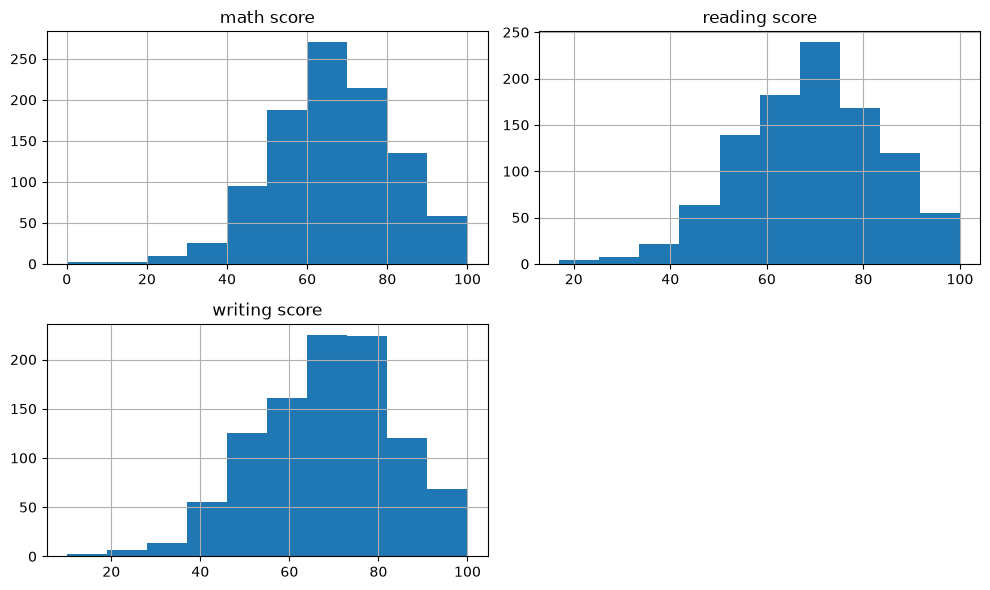

In [20]:
data.hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

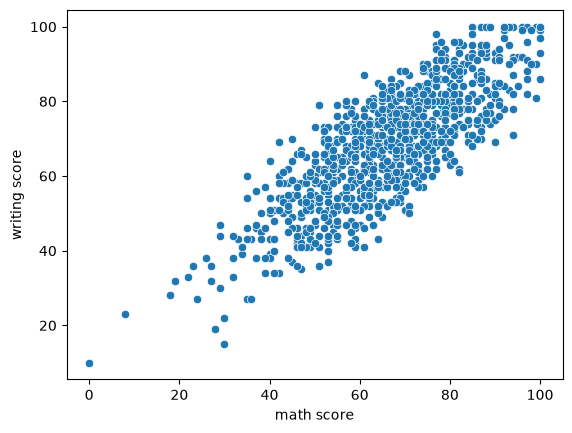

In [29]:
#visualize relationship between input and other features  ->relaion must be linear
sns.scatterplot(
    data=data,
    x="math score",
    y="writing score"
)
plt.show()

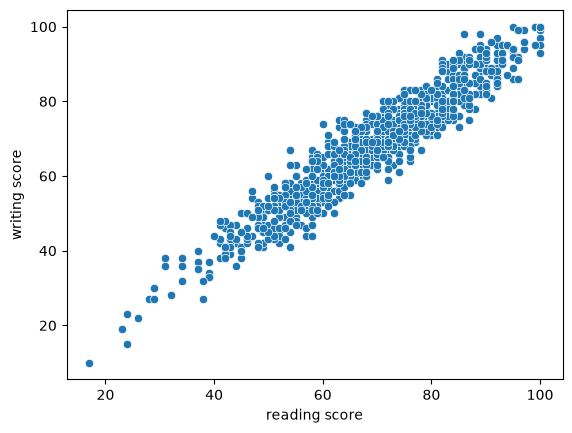

In [30]:
sns.scatterplot(
    data=data,
    x="reading score",
    y="writing score"
)
plt.show()

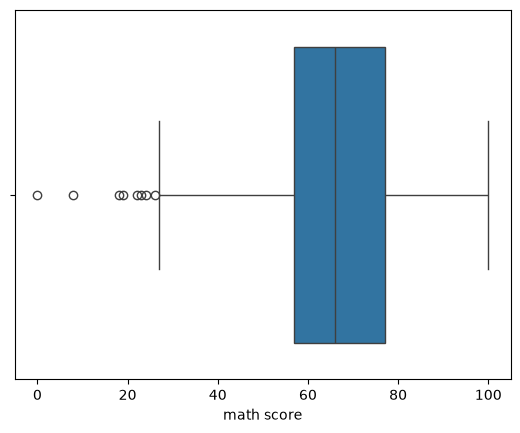

In [33]:
sns.boxplot(data=data, x="math score")
plt.show()

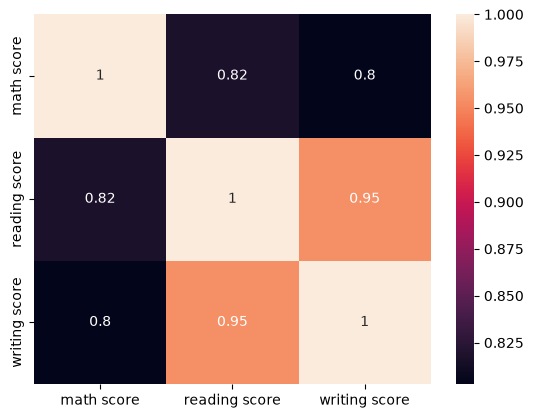

In [31]:
numeric_data = data.select_dtypes(
    include="number"
)

sns.heatmap(
    numeric_data.corr(),
    annot=True
)

plt.show()

In [49]:
x = data[["math score"]]
y = data["writing score"]

x_train, x_test, y_train, y_test = train_test_split( x, y, test_size = 0.2, random_state = 40)


In [50]:
model = LinearRegression()
model.fit(x_train, y_train)
print("intercept : ", model.intercept_)
print("coefficient : ", model.coef_)

intercept :  14.628352314531476
coefficient :  [0.80666577]


In [51]:
y_pred = model.predict(x_test)

In [52]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)

print("y_test dimensions:", y_test.ndim)
print("y_pred dimensions:", y_pred.ndim)

y_test shape: (200,)
y_pred shape: (200,)
y_test dimensions: 1
y_pred dimensions: 1


In [53]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

print(results.head())

     Actual  Predicted
204    42.0  62.221633
71     63.0  65.448296
594    99.0  88.841603
672    76.0  70.288290
14     58.0  54.961641
